# Implemntereting af single layer perceptron

## 1. Import af bibliotek

Matplotlib bruges til at visualisere træningsdataene og modellens beslutningsgrænse.

In [124]:
import matplotlib.pyplot as plt

## 2. Oprettelse af Perceptron-klassen

Klassen indeholder modellens vægte, bias og læringsrate. Den indeholder også metoder til aktivering, forudsigelse og træning.

In [125]:
# Opret Perceptron som en klasse der har værdierne vægt, bias og læringsrate

class Perceptron:
    def __init__(self, antal_inputs):
        # Der skal være en vægt for hvert input.
        # Nulstart gør modellen neutral, før den er blevet trænet.
        self.vægt = [0] * antal_inputs
        # Bias flytter beslutningsgrænsen uafhængigt af inputværdierne.
        self.bias = 0
        # En lille læringsrate giver mindre vægtjusteringer ad gangen.
        self.læringsrate = 0.001


    def aktiveringsfunktion(self, værdi):
        # aktiveringsfunktionen ReLU
        if værdi < 0:
            return 0
        else:
            return værdi


    def forudsig(self, inputs):
        # Start med bias, og læg hvert input ganget med sin vægt til.
        samlet_værdi = self.bias

        for i in range(len(inputs)):
            samlet_værdi += inputs[i] * self.vægt[i]
        return self.aktiveringsfunktion(samlet_værdi)

    def klassificer(self, inputs):
        return int(self.forudsig(inputs) >= 0.5)

    def træn(self, træningsdata, antal_epoker):
        # En epoke betyder, at modellen gennemgår hele datasættet én gang.
        for epoke in range(antal_epoker):
            for inputs, forventet in træningsdata:
                forudsigelse = self.forudsig(inputs)
                # Fejlen viser, om forudsigelsen skal op eller ned.
                fejl = forventet - forudsigelse

                # Vægtene justeres i retning af det korrekte svar.
                # Inputtet bestemmer, hvilke vægte der påvirkes.
                for i in range(len(self.vægt)):
                    self.vægt[i] += self.læringsrate * fejl * inputs[i]
                # Bias justeres også, så beslutningsgrænsen kan flyttes.
                self.bias += self.læringsrate * fejl

## 3. træningsdata

Hvert eksempel består af inputværdierne og det korrekte svar. 

In [126]:
import random

def generate_rows(num_rows):
    rows = []
    forventetErEn = 0

    for _ in range(num_rows):
        digits = [random.uniform(0.0, 1.0) for _ in range(2)]
        expected = int(sum(digits) >= 1.0)

        if expected == 1:
            forventetErEn += 1

        rows.append((digits, expected))

    print(forventetErEn)
    return rows
træningsdata = generate_rows(5000)
print(træningsdata[:5])
testdata = generate_rows(1000)
print(testdata[:5])


2513
[([0.31376691291880854, 0.08261336964235999], 0), ([0.5665806530953761, 0.7095743965496283], 1), ([0.3712862741649432, 0.06130173649273618], 0), ([0.5596441714379904, 0.9670551727914166], 1), ([0.4907876170291873, 0.5606522460892059], 1)]
483
[([0.7492252232034436, 0.9965559317124635], 1), ([0.9648868761686827, 0.38664768223401813], 1), ([0.7389365287951152, 0.48246840725404694], 1), ([0.1183709908360141, 0.8628819178462754], 0), ([0.027611369418200304, 0.48548372377935445], 0)]


## 4. Træning af modellen

Her oprettes en perceptron med to input. Modellen trænes derefter på OR-datasættet i 1000 epoker.

In [127]:
perceptron = Perceptron(len(træningsdata[0][0]))
perceptron.træn(træningsdata, 5)

## 5. Modellens forudsigelser

Sammenlignes modellens forudsigelse sammenlignes med det korrekte svar for hvert eksempel i træningsdataene.

In [128]:
def beregn_precision_recall(data, perceptron):
    # Pseudokode: Opret tre tællere, som opgør hvor godt klassifikationen virker.
    # TP: perceptronen forudsiger 1, og den rigtige værdi er også 1.
    tp = 0
    # FP: perceptronen forudsiger 1, selv om den rigtige værdi er 0.
    fp = 0
    # FN: perceptronen forudsiger 0, selv om den rigtige værdi er 1.
    fn = 0

    # Pseudokode: Gennemløb alle eksempler og sammenlign klassifikation med facit.
    for inputs, forventet in data:
        # Brug perceptronen til at lave en forudsigelse for det aktuelle input.
        forudsagt = perceptron.klassificer(inputs)

        # Sammenlign forudsigelsen med den rigtige værdi og opdatér den passende tæller.
        if forudsagt == 1 and forventet == 1:
            # Begge værdier er 1: modellen har fundet en positiv korrekt.
            tp += 1
        elif forudsagt == 1 and forventet == 0:
            # Modellen siger 1 forkert: den klassificerer en negativ som positiv.
            fp += 1
        elif forudsagt == 0 and forventet == 1:
            # Modellen siger 0 forkert: den overser en positiv klassifikation.
            fn += 1

    # Vis tællerne, så det er muligt at se typerne af fejl separat.
    print(tp, fp, fn)

    # Precision = TP / (TP + FP): andelen af positive forudsigelser, der er korrekte.
    # Recall = TP / (TP + FN): andelen af de positive eksempler, modellen finder.
    # Betingelsen undgår division med nul, hvis der ikke er positive eksempler at måle.
    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0

    # Returnér målingerne, så de kan bruges til at sammenligne trænings- og testdata.
    return precision, recall


# Beregn målingerne separat for træningssættet for at kontrollere modellens læring.
precision_træn, recall_træn = beregn_precision_recall(træningsdata, perceptron)
# Beregn målingerne separat for testsættet for at kontrollere modellen på ukendte data.
precision_test, recall_test = beregn_precision_recall(testdata, perceptron)

# Vis resultatet, så precision og recall kan sammenlignes mellem de to datasæt.
print("Træningsdata — precision:", precision_træn, "recall:", recall_træn)
print("Testdata — precision:", precision_test, "recall:", recall_test)


2505 32 8
483 6 0
Træningsdata — precision: 0.9873866771777691 recall: 0.996816553919618
Testdata — precision: 0.9877300613496932 recall: 1.0


## 6. Visualisering af træningsdata og beslutningsgrænse

Datapunkterne vises med forskellige farver alt efter deres klasse. Den røde linje viser perceptronens beslutningsgrænse.

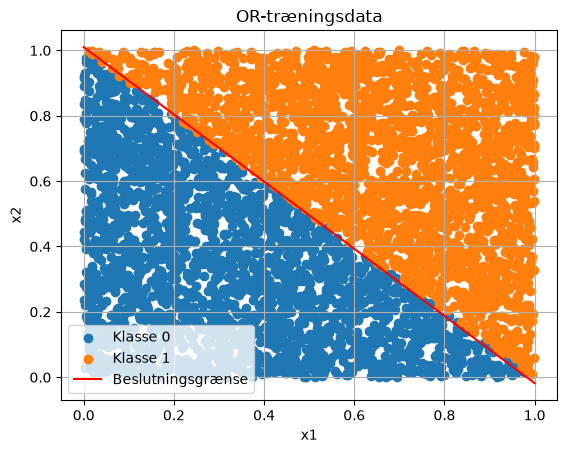

In [129]:
# Tegn datapunkterne med hver sin farve, så klasserne kan skelnes.
for klasse, farve, navn in [
    (0, "tab:blue", "Klasse 0"),
    (1, "tab:orange", "Klasse 1"),
]:
    punkter = [
        inputs for inputs, svar in træningsdata
        if svar == klasse
    ]
    plt.scatter(
        [punkt[0] for punkt in punkter],
        [punkt[1] for punkt in punkter],
        color=farve,
        label=navn,
    )

# Grænsen ligger, hvor vægt * input + bias = 0.
# Løs ligningen for x2 ved to x1-værdier for at tegne linjen.
tærskel = 0.5

x1_værdier = [0, 1]

if perceptron.vægt[1] != 0:
    x2_værdier = [
        (tærskel - perceptron.bias - perceptron.vægt[0] * x1)
        / perceptron.vægt[1]
        for x1 in x1_værdier
    ]
    plt.plot(x1_værdier, x2_værdier, color="red", label="Beslutningsgrænse")


plt.xlabel("x1")
plt.ylabel("x2")
plt.title("OR-træningsdata")
plt.legend()
plt.grid(True)
# Vis grafen i et separat vindue.
plt.show()